# MPIIGaze - Training GazeNet with the "Deep Learning from Scratch" code

Everything here runs on **NumPy only**, reusing the textbook's building blocks from `common/`:

| Textbook component | Used as |
|---|---|
| `common/layers.py`: `Convolution`, `Pooling`, `Relu`, `Affine` | GazeNet layers (unchanged) |
| `common/optimizer.py`: `SGD`, `Momentum`, `AdaGrad`, `Adam` | parameter updates (unchanged) |
| `common/gradient.py`: `numerical_gradient` | gradient check |
| `ch07/simple_convnet.py`: `SimpleConvNet` | template for `mpiigaze/gaze_net.py` |
| `common/trainer.py`: `Trainer` | template for `mpiigaze/trainer.py` |

What had to be added for gaze estimation (see the EDA notebook for why):

* `MeanSquaredLoss` (`mpiigaze/layers_ext.py`): regression instead of softmax classification.
* Non-square input (36x60) and a **head-pose concat** before the last `Affine` layer.
* Metric: mean **3D angular error** in degrees instead of accuracy.
* Protocol: **leave-one-person-out** on the standard evaluation subset (15 x 3000 eyes).

```
eye 1x36x60 -> Conv 20@5x5 -> ReLU -> Pool 2x2 -> Conv 50@5x5 -> ReLU -> Pool 2x2
            -> Affine 500 -> ReLU -> [concat head pose (2)] -> Affine 2 -> (pitch, yaw) -> MSE
```

In [1]:
import sys, os, json, glob, time
sys.path.append(os.path.join(os.pardir, os.pardir))  # repository root: common/ and mpiigaze/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpiigaze import dataset, plot_style
from mpiigaze.gaze_net import GazeNet
from mpiigaze.trainer import RegressionTrainer
from mpiigaze.layers_ext import angular_error
from mpiigaze.plot_style import BLUE, ORANGE, AQUA, SEQ_CMAP, TEXT2
plot_style.apply()
YELLOW = '#eda100'   # categorical slot 4
RESULT_DIR = os.path.join(os.pardir, 'results')
FIG_DIR = os.path.join(os.pardir, 'figures')

(x_tr, p_tr, t_tr), (x_te, p_te, t_te) = dataset.load_mpiigaze(test_person='p00')
print('train:', x_tr.shape, p_tr.shape, t_tr.shape)
print('test :', x_te.shape, p_te.shape, t_te.shape)

train: (42000, 1, 36, 60) (42000, 2) (42000, 2)
test : (3000, 1, 36, 60) (3000, 2) (3000, 2)


## 1. Gradient check
Backprop through the new loss and the concat must match numerical differentiation (textbook ch05 method).

In [2]:
np.random.seed(0)
small = GazeNet(input_dim=(1, 12, 16), hidden_size=10,
                conv_params=({'filter_num': 3, 'filter_size': 3, 'pad': 0, 'stride': 1},
                             {'filter_num': 4, 'filter_size': 3, 'pad': 0, 'stride': 1}))
x, p, t = np.random.rand(3, 1, 12, 16), np.random.randn(3, 2) * 0.2, np.random.randn(3, 2) * 0.2
gn, gb = small.numerical_gradient(x, p, t), small.gradient(x, p, t)
pd.Series({k: np.abs(gn[k] - gb[k]).mean() for k in sorted(gn)}, name='mean |numerical - backprop|').to_frame().T

,W1,W2,W3,W4,b1,b2,b3,b4
mean |numerical - backprop|,1.833050e-11,1.045785e-11,3.643023e-12,7.437411e-12,1.068893e-11,9.994727e-12,3.191603e-12,1.203904e-11


## 2. Optimizer comparison (textbook ch06 experiment, on gaze data)
To keep it fast, each optimizer trains the same initial network on a random 6,000-sample subset for 3 epochs
and is evaluated on test person p00.

In [3]:
rng = np.random.default_rng(0)
sub = rng.choice(len(x_tr), 6000, replace=False)
optimizers = [('SGD', {'lr': 0.01}, BLUE), ('Momentum', {'lr': 0.01}, ORANGE),
              ('AdaGrad', {'lr': 0.01}, AQUA), ('Adam', {'lr': 0.001}, YELLOW)]
np.random.seed(1)
init = GazeNet().params
opt_runs = {}
for name, param, _ in optimizers:
    np.random.seed(2)
    net = GazeNet()
    for k in net.params: net.params[k][...] = init[k]
    tr = RegressionTrainer(net, x_tr[sub], p_tr[sub], t_tr[sub], x_te, p_te, t_te, epochs=3,
                           optimizer=name, optimizer_param=param, evaluate_sample_num_per_epoch=3000, verbose=False)
    err = tr.train()
    opt_runs[name] = (tr.train_loss_list, tr.test_err_list, err)
    print('%-9s final test error: %.2f deg' % (name, err))

SGD       final test error: 6.86 deg


Momentum  final test error: 5.78 deg


AdaGrad   final test error: 6.35 deg


Adam      final test error: 5.43 deg


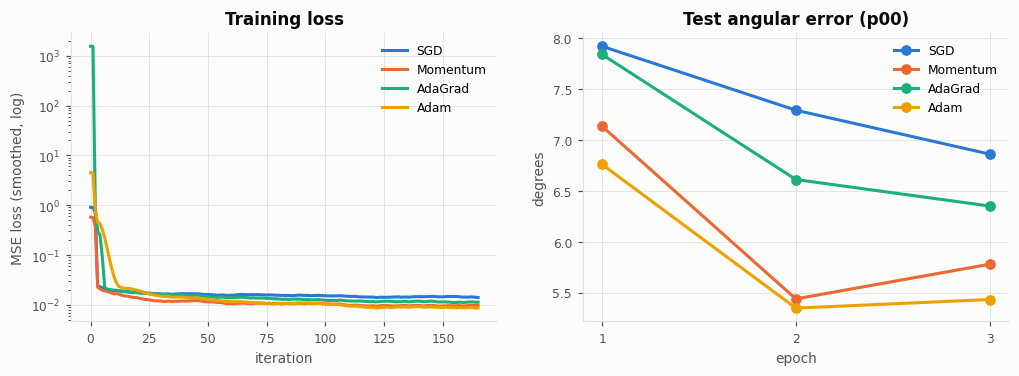

In [4]:
def smooth(v, k=15):
    return np.convolve(v, np.ones(k) / k, mode='valid')
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for name, _, c in optimizers:
    loss, errs, _ = opt_runs[name]
    axes[0].plot(smooth(loss), color=c, label=name)
    axes[1].plot(range(1, len(errs) + 1), errs, color=c, marker='o', ms=6, label=name)
axes[0].set_yscale('log'); axes[0].set_xlabel('iteration'); axes[0].set_ylabel('MSE loss (smoothed, log)')
axes[0].set_title('Training loss'); axes[0].legend()
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('degrees'); axes[1].set_title('Test angular error (p00)')
axes[1].set_xticks([1, 2, 3]); axes[1].legend()
fig.savefig(os.path.join(FIG_DIR, 'optimizer_comparison.png')); plt.show()

## 3. Does the head-pose input help? (ablation, same 6,000-sample setting, Adam)

In [5]:
abl = {}
for use_pose in (True, False):
    np.random.seed(2)
    net = GazeNet(pose_size=2 if use_pose else 0)
    tr = RegressionTrainer(net, x_tr[sub], p_tr[sub] if use_pose else None, t_tr[sub],
                           x_te, p_te if use_pose else None, t_te, epochs=3, optimizer='Adam',
                           optimizer_param={'lr': 0.001}, evaluate_sample_num_per_epoch=3000, verbose=False)
    abl['with head pose' if use_pose else 'image only'] = tr.train()
pd.Series(abl, name='test error (deg), p00').round(2).to_frame()

,"test error (deg), p00"
with head pose,5.63
image only,6.08


## 4. Leave-one-person-out results (full training)

Produced by `mpiigaze/train.py --test-person pXX --epochs 5` for all 15 participants
(Adam, lr 0.001 decayed x0.8 per epoch, batch 100, 42,000 training eyes per fold).

In [6]:
folds = []
for path in sorted(glob.glob(os.path.join(RESULT_DIR, 'result_p*.json'))):
    with open(path) as f:
        folds += json.load(f)['folds']
res = pd.DataFrame([{'person': r['test_person'], 'baseline (deg)': r['baseline_deg'],
                     'GazeNet (deg)': r['test_err_deg']} for r in folds]).set_index('person')
res.loc['mean'] = res.mean()
res.round(2).T

person,p00,p01,p02,p03,p04,p05,p06,p07,p08,p09,p10,p11,p12,p13,p14,mean
baseline (deg),8.43,8.63,9.00,9.60,8.97,9.73,10.34,9.49,9.61,8.97,8.66,8.43,8.60,9.00,10.75,9.21
GazeNet (deg),5.20,7.36,5.27,7.18,7.21,7.11,6.34,8.06,6.87,8.57,6.16,5.51,6.51,6.87,5.48,6.65


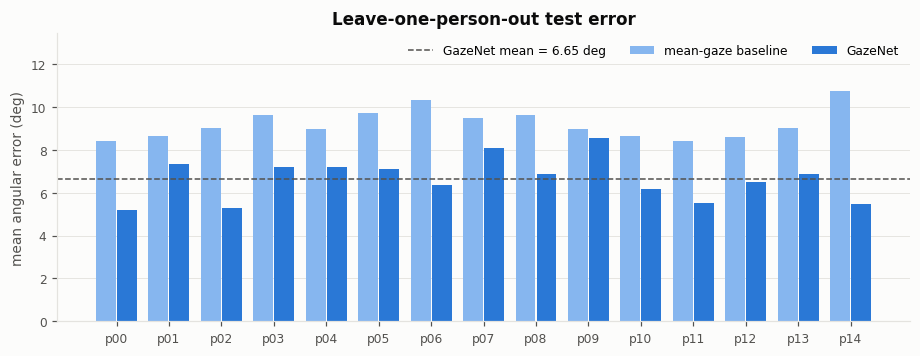

In [7]:
r = res.drop('mean')
x = np.arange(len(r)); w = 0.38
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(x - w / 2 - 0.01, r['baseline (deg)'], w, color='#86b6ef', label='mean-gaze baseline')
ax.bar(x + w / 2 + 0.01, r['GazeNet (deg)'], w, color=BLUE, label='GazeNet')
ax.axhline(res.loc['mean', 'GazeNet (deg)'], color=TEXT2, lw=1, ls='--',
           label='GazeNet mean = %.2f deg' % res.loc['mean', 'GazeNet (deg)'])
ax.set_xticks(x); ax.set_xticklabels(r.index); ax.set_ylabel('mean angular error (deg)')
ax.set_title('Leave-one-person-out test error'); ax.legend(loc='upper right', ncol=3); ax.grid(axis='x', visible=False)
ax.set_ylim(0, r.values.max() * 1.25)
fig.savefig(os.path.join(FIG_DIR, 'lopo_results.png')); plt.show()

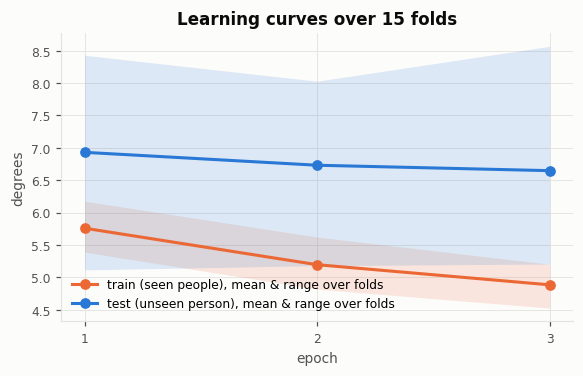

In [8]:
te = np.array([r['test_err'] for r in folds]); tr_ = np.array([r['train_err'] for r in folds])
ep = np.arange(1, te.shape[1] + 1)
fig, ax = plt.subplots(figsize=(6, 3.4))
for arr, c, name in ((tr_, ORANGE, 'train (seen people)'), (te, BLUE, 'test (unseen person)')):
    ax.fill_between(ep, arr.min(0), arr.max(0), color=c, alpha=0.15, linewidth=0)
    ax.plot(ep, arr.mean(0), color=c, marker='o', ms=6, label=name + ', mean & range over folds')
ax.set_xlabel('epoch'); ax.set_ylabel('degrees'); ax.set_xticks(ep)
ax.set_title('Learning curves over 15 folds'); ax.legend()
fig.savefig(os.path.join(FIG_DIR, 'learning_curves.png')); plt.show()

## 5. Error analysis on test person p00

p00 mean error 5.20 deg, median 5.03 deg, 90th percentile 8.42 deg


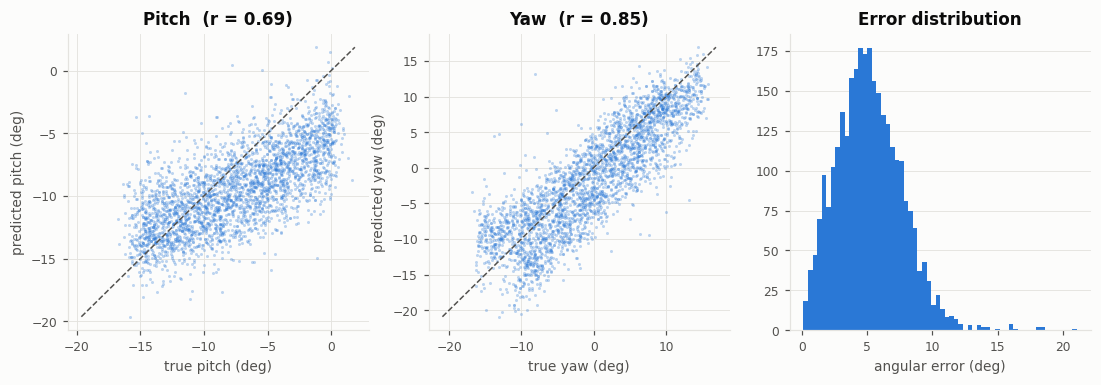

In [9]:
net = GazeNet()
net.load_params(os.path.join(RESULT_DIR, 'gazenet_p00.pkl'))
pred = np.concatenate([net.predict(x_te[i:i + 500], p_te[i:i + 500]) for i in range(0, len(x_te), 500)])
err = angular_error(pred, t_te)
print('p00 mean error %.2f deg, median %.2f deg, 90th percentile %.2f deg' % (err.mean(), np.median(err), np.percentile(err, 90)))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, k, name in ((axes[0], 0, 'pitch'), (axes[1], 1, 'yaw')):
    tt, pp = np.degrees(t_te[:, k]), np.degrees(pred[:, k])
    ax.scatter(tt, pp, s=4, alpha=0.3, color=BLUE, linewidths=0)
    lim = [min(tt.min(), pp.min()), max(tt.max(), pp.max())]
    ax.plot(lim, lim, color=TEXT2, lw=1, ls='--')
    ax.set_xlabel('true %s (deg)' % name); ax.set_ylabel('predicted %s (deg)' % name)
    ax.set_title('%s  (r = %.2f)' % (name.capitalize(), np.corrcoef(tt, pp)[0, 1]))
axes[2].hist(err, bins=60, color=BLUE); axes[2].set_xlabel('angular error (deg)')
axes[2].set_title('Error distribution'); axes[2].grid(axis='x', visible=False)
fig.savefig(os.path.join(FIG_DIR, 'p00_errors.png')); plt.show()

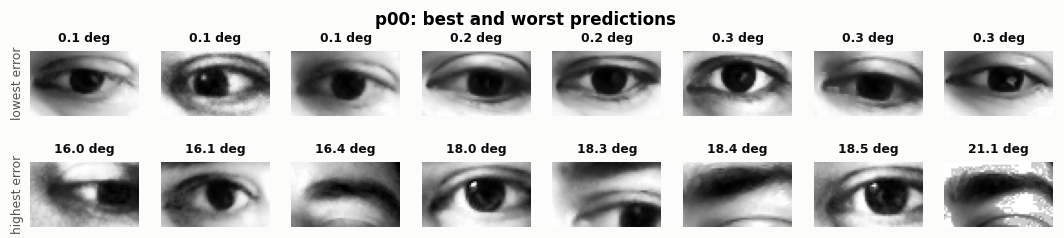

In [10]:
order = np.argsort(err)
fig, axes = plt.subplots(2, 8, figsize=(12, 2.4))
for row, idxs, label in ((0, order[:8], 'lowest error'), (1, order[-8:], 'highest error')):
    for ax, i in zip(axes[row], idxs):
        ax.imshow(x_te[i, 0], cmap='gray'); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for s in ax.spines.values(): s.set_visible(False)
        ax.set_title('%.1f deg' % err[i], fontsize=8)
    axes[row, 0].set_ylabel(label, fontsize=8)
plt.suptitle('p00: best and worst predictions', fontsize=11, fontweight='bold'); plt.show()

## 6. Summary

**Result.** Leave-one-person-out mean angular error is **6.65 deg** (sd 0.97 over 15 people), against **9.21 deg**
for the mean-gaze baseline (28% lower). GazeNet beats the baseline for every participant, from 5.20 deg (p00) to
8.57 deg (p09). Zhang et al. (CVPR 2015) report 6.3 deg for their LeNet-based GazeNet on the same protocol; this
NumPy-only reimplementation with 3 epochs lands close to that.

**Generalization gap.** After 3 epochs the error on the people seen in training is 4.9 deg, but on the unseen person
it is 6.65 deg and barely improves after epoch 1. Differences *between people* dominate, so more epochs alone will not
help much. More diverse data, augmentation or regularization would.

**Optimizers** (6,000 samples, 3 epochs): Adam 5.43 < Momentum 5.78 < AdaGrad 6.35 < SGD 6.86 deg. This is the same
ordering as the textbook's ch06 MNIST comparison.

**Head pose** (same small setting, single run): 5.63 deg with pose vs. 6.08 deg image only. A modest gain, consistent with
the weak gaze-head pose correlation found in the EDA. Runs differ by ~0.2 deg with different initializations
(compare Adam above), so treat this as indicative.

**Error analysis (p00).** Yaw is predicted well (r = 0.85); pitch less so (r = 0.69). Predictions are pulled
toward the mean pitch: its range is narrow, and looking down narrows the eyelid opening.

**Limitations / next steps.** Inputs are not zero-centered, which causes a large loss spike in the first iterations
(visible for AdaGrad). Mean-centering, data augmentation, and the textbook's Dropout / BatchNormalization layers
(ch06) are the obvious next experiments.